---
title: "Marketing Mix Modeling"
author: "Fabian"
date: "2024-5-06"
categories: ["Marketing Analytics"]
image: thumbnail.png
format:
  html:
    code-fold: false
    toc: true
jupyter: python3
freeze: true
---

## Marketing Mix Modeling (MMM): a practical walkthrough

Marketing Mix Modeling estimates how different marketing channels contribute to sales. A useful MMM workflow should do more than fit a regression line: it should make the data-generating assumptions visible, check whether channels move together, and inspect whether model errors have structure.

In this notebook we will:

- simulate daily spend and sales data with trend, weekly seasonality, campaign variation, and noise;
- visualize channel spend, sales, and channel correlations;
- fit an OLS model with simple controls for trend and day of week;
- inspect model fit, residuals, and channel coefficient estimates.

**Important:** this is a teaching example. Production MMM usually needs additional pieces such as adstock, saturation curves, holdout validation, budget constraints, and causal calibration from experiments.

### 1. Imports and chart settings

In [1]:
%matplotlib inline

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as sm
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (11, 6),
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "legend.frameon": False,
})

CHANNELS = ["TV", "Radio", "Social_Media"]
CHANNEL_LABELS = {
    "TV": "TV",
    "Radio": "Radio",
    "Social_Media": "Social media",
}
CHANNEL_COLORS = {
    "TV": "#2563eb",
    "Radio": "#f97316",
    "Social_Media": "#16a34a",
}


### 2. Simulate data

The original version used perfectly increasing values, which made the regression look unrealistically perfect. Here we create a 90-day example with a baseline, trend, weekly seasonality, independent channel variation, and random noise. That gives the model something closer to a real diagnostic problem.

In [2]:
rng = np.random.default_rng(7)

dates = pd.date_range("2023-01-01", periods=90, freq="D")
day = np.arange(len(dates))
weekly = np.sin(2 * np.pi * day / 7)

# Simulated channel spend with different patterns and campaign pulses.
tv = 1200 + 260 * np.sin(2 * np.pi * day / 30) + rng.normal(0, 95, len(day))
tv[[18, 19, 20, 58, 59, 60]] += 360

radio = 620 + 95 * np.cos(2 * np.pi * day / 14) + rng.normal(0, 55, len(day))
radio[[35, 36, 37, 38]] += 180

social = 260 + 3.1 * day + 65 * weekly + rng.normal(0, 45, len(day))
social[[24, 25, 26, 70, 71, 72]] += 140

df = pd.DataFrame({
    "Date": dates,
    "TV": np.clip(tv, 650, None).round(0),
    "Radio": np.clip(radio, 320, None).round(0),
    "Social_Media": np.clip(social, 120, None).round(0),
})

df["Trend"] = day
df["Day_of_Week"] = df["Date"].dt.day_name()

base_sales = 2400
trend_effect = 12 * day
seasonality_effect = 175 * weekly
noise = rng.normal(0, 140, len(day))

df["Sales"] = (
    base_sales
    + 0.55 * df["TV"]
    + 1.10 * df["Radio"]
    + 2.35 * df["Social_Media"]
    + trend_effect
    + seasonality_effect
    + noise
).round(0)

for column in CHANNELS + ["Sales"]:
    df[f"{column}_7d_avg"] = df[column].rolling(window=7, min_periods=1).mean()

display(df.head())


,Date,TV,Radio,Social_Media,Trend,Day_of_Week,Sales,TV_7d_avg,Radio_7d_avg,Social_Media_7d_avg,Sales_7d_avg
0,2023-01-01,1200.0,714.0,240.0,0,Sunday,4408.0,1200.0,714.000000,240.000000,4408.00
1,2023-01-02,1282.0,742.0,291.0,1,Monday,4569.0,1241.0,728.000000,265.500000,4488.50
2,2023-01-03,1280.0,661.0,358.0,2,Tuesday,5108.0,1254.0,705.666667,296.333333,4695.00
3,2023-01-04,1268.0,699.0,284.0,3,Wednesday,4850.0,1257.5,704.000000,293.250000,4733.75
4,2023-01-05,1350.0,599.0,237.0,4,Thursday,4266.0,1276.0,683.000000,282.000000,4640.20


### 3. Explore the data

Before modeling, check the two failure modes that make MMM hard: time patterns and correlated media channels. If channels rise and fall together, the model may struggle to assign credit cleanly even when total prediction accuracy looks good.

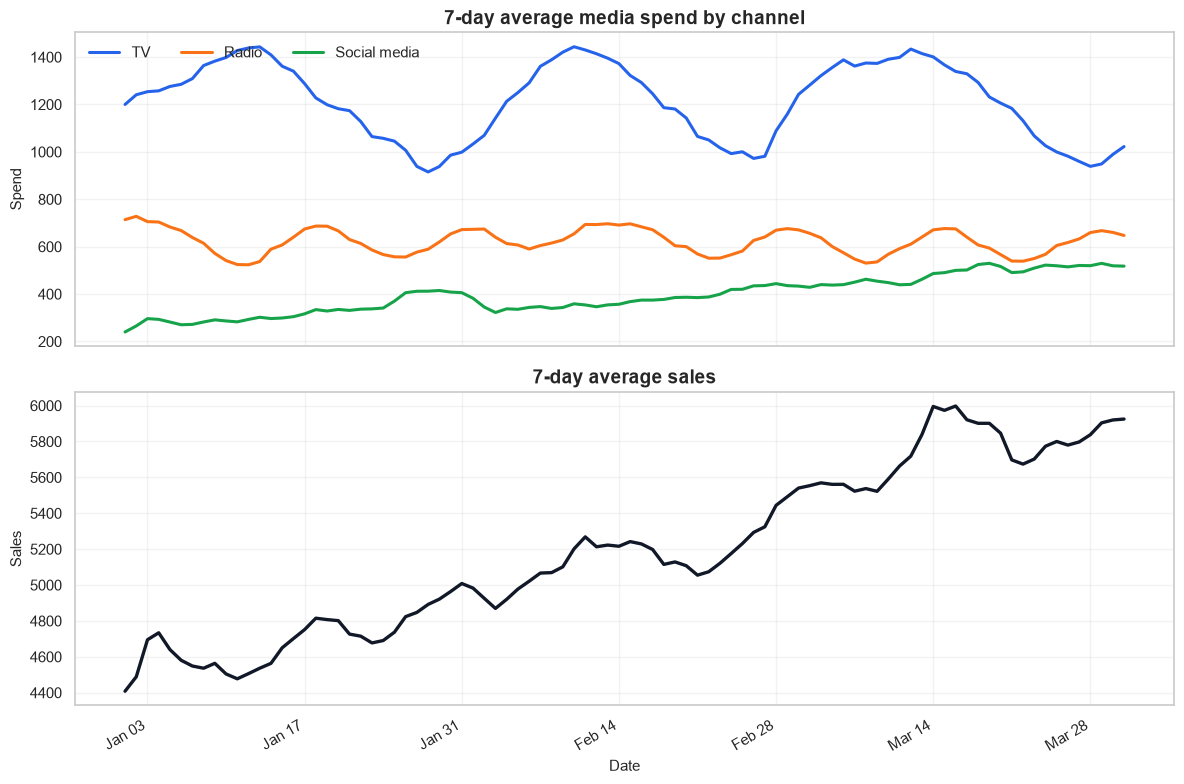

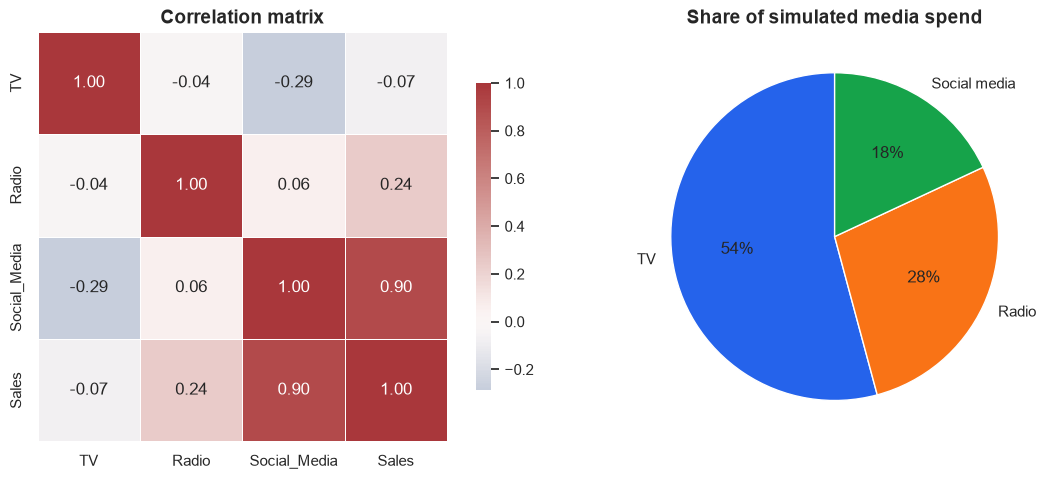

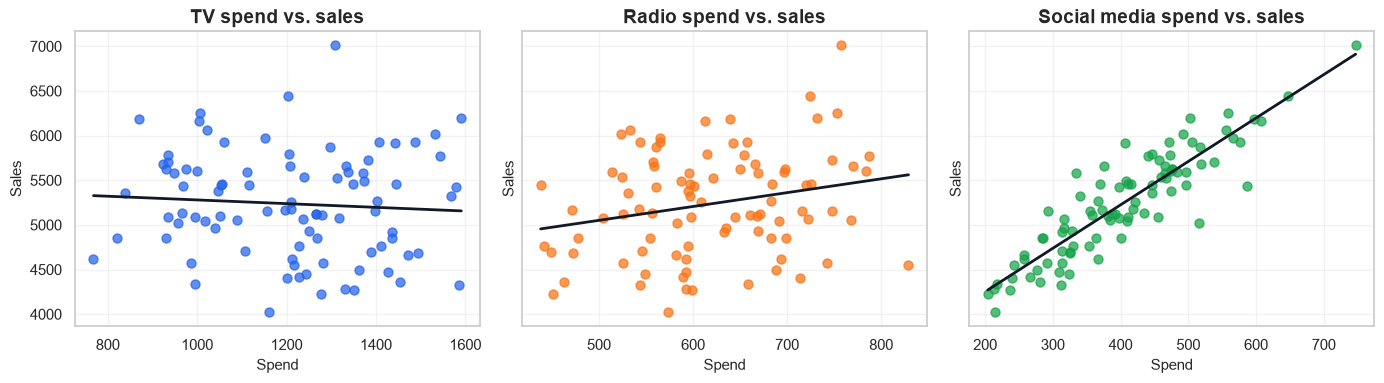

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, height_ratios=[1, 1])

for channel in CHANNELS:
    axes[0].plot(
        df["Date"],
        df[f"{channel}_7d_avg"],
        label=CHANNEL_LABELS[channel],
        color=CHANNEL_COLORS[channel],
        linewidth=2.2,
    )

axes[0].set_title("7-day average media spend by channel")
axes[0].set_ylabel("Spend")
axes[0].legend(ncol=3, loc="upper left")

axes[1].plot(df["Date"], df["Sales_7d_avg"], color="#111827", linewidth=2.4)
axes[1].set_title("7-day average sales")
axes[1].set_ylabel("Sales")
axes[1].set_xlabel("Date")
axes[1].xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

for ax in axes:
    ax.grid(True, alpha=0.25)

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

corr = df[CHANNELS + ["Sales"]].corr()
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    square=True,
    linewidths=0.5,
    ax=axes[0],
    cbar_kws={"shrink": 0.75},
)
axes[0].set_title("Correlation matrix")

spend_share = df[CHANNELS].sum().rename(index=CHANNEL_LABELS)
axes[1].pie(
    spend_share,
    labels=spend_share.index,
    autopct="%1.0f%%",
    startangle=90,
    colors=[CHANNEL_COLORS[channel] for channel in CHANNELS],
    wedgeprops={"linewidth": 1, "edgecolor": "white"},
)
axes[1].set_title("Share of simulated media spend")

fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, channel in zip(axes, CHANNELS):
    sns.regplot(
        data=df,
        x=channel,
        y="Sales",
        ax=ax,
        scatter_kws={"alpha": 0.72, "s": 42, "color": CHANNEL_COLORS[channel]},
        line_kws={"color": "#111827", "linewidth": 2},
        ci=None,
    )
    ax.set_title(f"{CHANNEL_LABELS[channel]} spend vs. sales")
    ax.set_xlabel("Spend")
    ax.grid(True, alpha=0.25)

axes[0].set_ylabel("Sales")
fig.tight_layout()
plt.show()


### 4. Fit and summarize the model

We model sales as a function of the three media channels, plus a linear trend and day-of-week controls. Those controls are not a full MMM treatment, but they keep obvious time patterns from being incorrectly credited to media.

In [4]:
model = sm.ols("Sales ~ TV + Radio + Social_Media + Trend + C(Day_of_Week)", data=df).fit()

model_metrics = pd.DataFrame({
    "Metric": ["R-squared", "Adjusted R-squared", "AIC", "BIC", "F-test p-value"],
    "Value": [model.rsquared, model.rsquared_adj, model.aic, model.bic, model.f_pvalue],
})
model_metrics["Value"] = model_metrics["Value"].map(lambda value: f"{value:,.4g}")

def format_p_value(value):
    return "<0.001" if value < 0.001 else f"{value:.3f}"

coef_table = pd.DataFrame({
    "Channel": [CHANNEL_LABELS[channel] for channel in CHANNELS],
    "Estimated incremental sales per spend unit": [model.params[channel] for channel in CHANNELS],
    "CI low": [model.conf_int().loc[channel, 0] for channel in CHANNELS],
    "CI high": [model.conf_int().loc[channel, 1] for channel in CHANNELS],
    "p-value": [format_p_value(model.pvalues[channel]) for channel in CHANNELS],
})
coef_table = coef_table.sort_values("Estimated incremental sales per spend unit", ascending=False)

print("Model fit")
display(model_metrics)

print("Channel coefficient estimates")
display(coef_table.round({
    "Estimated incremental sales per spend unit": 2,
    "CI low": 2,
    "CI high": 2,
}))


Model fit


,Metric,Value
0,R-squared,0.9635
1,Adjusted R-squared,0.9589
2,AIC,"1,126"
3,BIC,"1,154"
4,F-test p-value,1.777e-52


Channel coefficient estimates


,Channel,Estimated incremental sales per spend unit,CI low,CI high,p-value
2,Social media,2.59,2.12,3.07,<0.001
1,Radio,1.26,0.98,1.55,<0.001
0,TV,0.50,0.37,0.63,<0.001


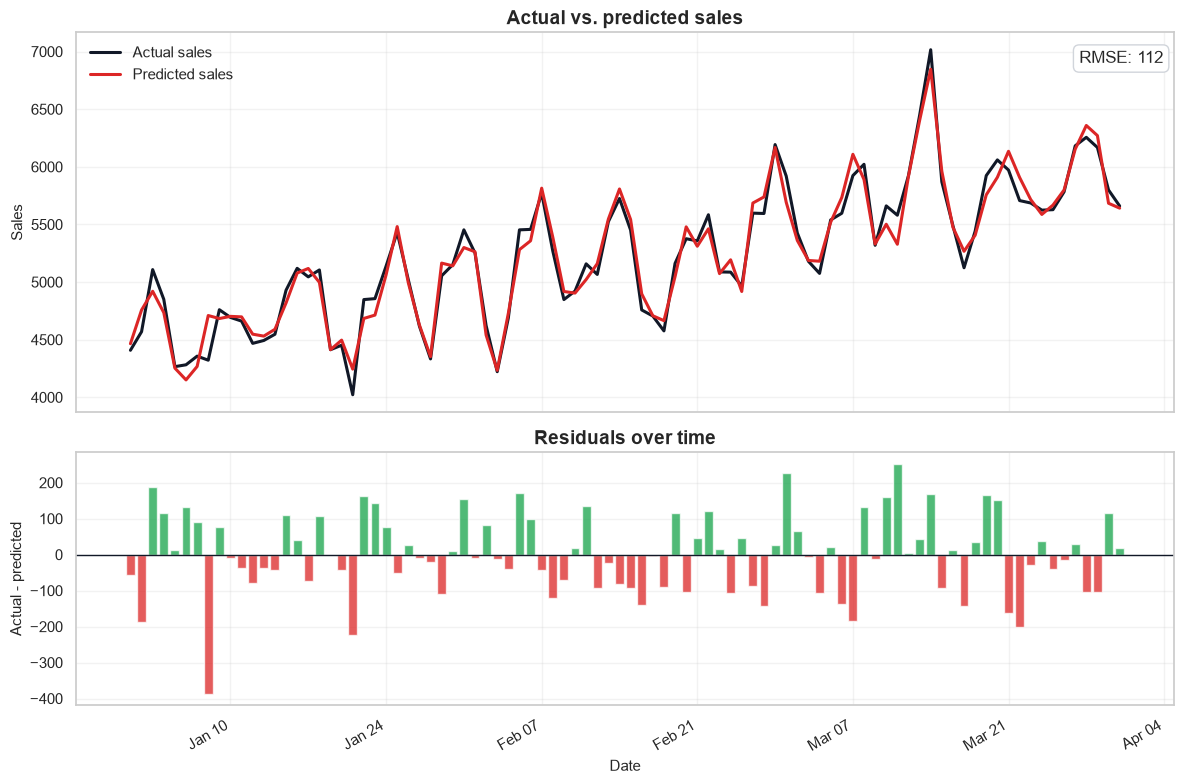

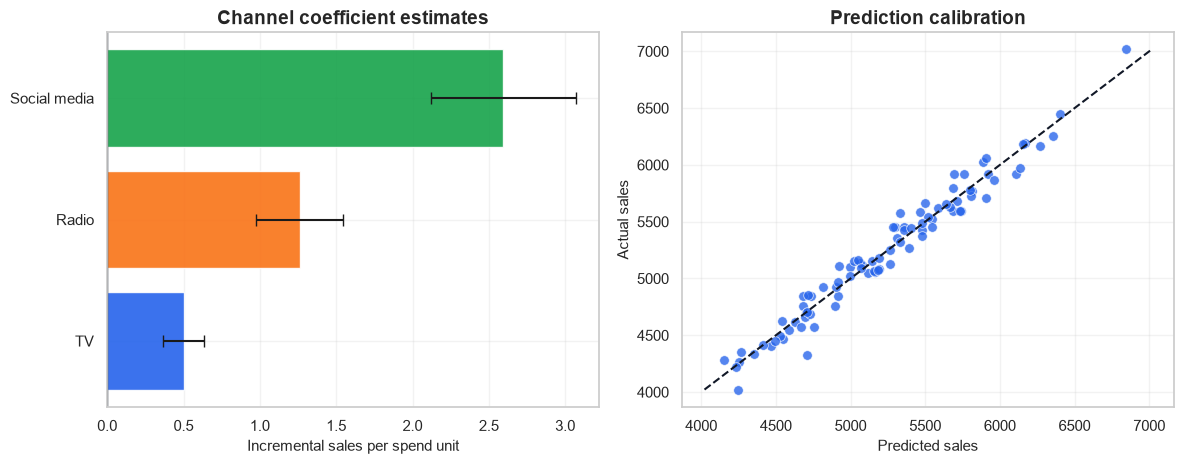

In [5]:
plot_df = df.copy()
plot_df["Sales_pred"] = model.predict(plot_df)
plot_df["Residuals"] = model.resid
rmse = np.sqrt(np.mean(np.square(plot_df["Residuals"])))

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, height_ratios=[1.2, 0.8])

axes[0].plot(plot_df["Date"], plot_df["Sales"], color="#111827", linewidth=2.2, label="Actual sales")
axes[0].plot(plot_df["Date"], plot_df["Sales_pred"], color="#dc2626", linewidth=2.2, label="Predicted sales")
axes[0].set_title("Actual vs. predicted sales")
axes[0].set_ylabel("Sales")
axes[0].legend(loc="upper left")
axes[0].text(
    0.99,
    0.92,
    f"RMSE: {rmse:,.0f}",
    transform=axes[0].transAxes,
    ha="right",
    bbox={"boxstyle": "round,pad=0.35", "facecolor": "white", "edgecolor": "#d1d5db"},
)

axes[1].bar(plot_df["Date"], plot_df["Residuals"], color=np.where(plot_df["Residuals"] >= 0, "#16a34a", "#dc2626"), alpha=0.75)
axes[1].axhline(0, color="#111827", linewidth=1)
axes[1].set_title("Residuals over time")
axes[1].set_ylabel("Actual - predicted")
axes[1].set_xlabel("Date")
axes[1].xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

for ax in axes:
    ax.grid(True, alpha=0.25)

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
coef_plot = coef_table.sort_values("Estimated incremental sales per spend unit")
y_pos = np.arange(len(coef_plot))
coef_values = coef_plot["Estimated incremental sales per spend unit"].to_numpy()
ci_low = coef_plot["CI low"].to_numpy()
ci_high = coef_plot["CI high"].to_numpy()

axes[0].barh(
    y_pos,
    coef_values,
    xerr=[coef_values - ci_low, ci_high - coef_values],
    color=[CHANNEL_COLORS[channel] for channel in ["TV", "Radio", "Social_Media"] if CHANNEL_LABELS[channel] in coef_plot["Channel"].to_list()],
    alpha=0.9,
    capsize=4,
)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(coef_plot["Channel"])
axes[0].set_xlabel("Incremental sales per spend unit")
axes[0].set_title("Channel coefficient estimates")
axes[0].axvline(0, color="#111827", linewidth=1)

sns.scatterplot(data=plot_df, x="Sales_pred", y="Sales", ax=axes[1], color="#2563eb", s=48, alpha=0.78)
min_sales = min(plot_df["Sales"].min(), plot_df["Sales_pred"].min())
max_sales = max(plot_df["Sales"].max(), plot_df["Sales_pred"].max())
axes[1].plot([min_sales, max_sales], [min_sales, max_sales], color="#111827", linestyle="--", linewidth=1.5)
axes[1].set_title("Prediction calibration")
axes[1].set_xlabel("Predicted sales")
axes[1].set_ylabel("Actual sales")

for ax in axes:
    ax.grid(True, alpha=0.25)

fig.tight_layout()
plt.show()


### 5. Interpret the results

The channel coefficients estimate the expected change in sales for one additional unit of spend, holding the other modeled variables constant. In this simulated data, social media has the largest per-unit coefficient because we built the dataset that way. TV still matters, but its spend level is higher, so per-unit coefficient size and total budget share should be interpreted together.

A good MMM readout separates three questions:

- **Fit:** Does the model explain sales movement reasonably well?
- **Attribution:** Which channels have reliable incremental effects after controls?
- **Diagnostics:** Are residuals randomly scattered, or do they show time patterns that the model missed?

The residual plot is especially useful. Runs of positive or negative residuals suggest the model is missing a driver such as promotion timing, price changes, holidays, inventory constraints, or nonlinear media response.

### 6. What this simple model leaves out

OLS is a useful first pass, but production MMM normally goes further:

- **Adstock:** media can keep affecting sales after the spend occurs.
- **Saturation:** each additional dollar usually has diminishing returns.
- **Holdout validation:** fit should be tested on future periods, not only in-sample.
- **Calibration:** experiment results or lift tests can anchor causal estimates.
- **Business constraints:** budget recommendations need minimums, maximums, seasonality, and operational constraints.

The main takeaway is not that OLS is a complete MMM system. It is that a clear notebook should make the modeling assumptions, visual diagnostics, and limitations easy to inspect.